# Green Smart Campus: Predicting Energy Saved
**Professional Training in AI 1 - Project 1**

This notebook covers **Stages 1 to 4** (data description, preprocessing and analysis, modeling and tuning, evaluation).
Stage 5 (deployment) is in `app.py` and the `models/` folder, with instructions in `README.md`.

Run the cells from top to bottom. Everything is repeatable because a fixed random seed (42) is used.

In [1]:
import os, json, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import sklearn
from scipy.stats import pearsonr, spearmanr, zscore
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from CRCTargetEncoder import CRCTargetEncoder      # our custom encoder from the encoding assignment

RANDOM_STATE = 42
TARGET = 'Total_Energy_Saved_kWh'
sns.set_theme(style='whitegrid')
os.makedirs('figures', exist_ok=True)
os.makedirs('models', exist_ok=True)


def save_fig(name):
    plt.savefig(f'figures/{name}.png', dpi=120, bbox_inches='tight')


print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)

scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.5.4


# Stage 1: Data description

**Source:** `<<ADD THE NAME AND LINK OF WHERE YOU DOWNLOADED THE DATASET (Kaggle / GitHub / other)>>`

**Problem:** A smart campus records weather, solar, water, waste and energy readings for three buildings.
We want to **predict `Total_Energy_Saved_kWh`** (the energy saved) from the other measurements, so that
facility managers can estimate expected savings from sensor readings.

**Task type:** supervised **regression** (the target is a number).

| Column | Type | Meaning (taken from the column name and unit) |
|---|---|---|
| Building_ID | categorical (B1, B2, B3) | Campus building |
| Day_Type | categorical (Weekday, Weekend) | Type of day |
| Is_Peak_Hour | binary (0/1) | 1 if the record is in a peak-demand hour |
| Water_Usage_Liters | numeric | Water used |
| Waste_Produced_Kg | numeric | Waste produced |
| Recycled_Waste_Kg | numeric | Waste recycled |
| Occupancy_Level | numeric (0.3 to 1.0) | Share of the building that is occupied |
| Temperature_C | numeric | Air temperature |
| Humidity_% | numeric | Relative humidity |
| Cloud_Cover_% | numeric | Share of the sky covered by cloud |
| Wind_Speed_kmph | numeric | Wind speed |
| Dew_Point_C | numeric | Dew point temperature |
| Precipitation_mm | numeric | Rainfall |
| Beam_Irradiance_Wm2 | numeric | Direct sunlight power per square metre |
| Diffuse_Irradiance_Wm2 | numeric | Scattered sunlight power per square metre |
| Reflected_Irradiance_Wm2 | numeric | Reflected sunlight power per square metre |
| Solar_Generation_kWh | numeric | Electricity generated by the solar panels |
| Energy_Consumption_kWh | numeric | Electricity consumed |
| **Total_Energy_Saved_kWh** | numeric (**target**) | Energy saved |

*If the dataset page defines a column differently, update this table.*

In [2]:
df = pd.read_csv('data/green_smart_campus_dataset.csv')
print('Rows, columns:', df.shape)
print()
print(df.head().T.to_string())
print()
df.info()

Rows, columns: (2673, 19)

                                   0           1           2           3           4
Building_ID                       B3          B1          B3          B3          B1
Water_Usage_Liters        913.667751  964.267749  829.522709  452.325517  750.507765
Waste_Produced_Kg          29.455517    9.522298   24.978949   13.354818   23.271759
Recycled_Waste_Kg          10.696019    9.006565   13.704484     2.71474    8.476506
Occupancy_Level                 0.66        0.31        0.49        0.66         0.7
Temperature_C               6.837479    4.792358    3.706635    0.467803   17.053222
Humidity_%                 39.158686   38.854212   77.352313   69.746707    88.71266
Cloud_Cover_%              87.924904   16.247915    6.439295   26.918644   60.694541
Wind_Speed_kmph            12.092251   20.928686     7.95016    8.471074   18.790122
Dew_Point_C                 7.757724    6.830361    1.910026   -3.801616    22.87367
Precipitation_mm            2.768609  

In [3]:
print('Summary statistics of the numeric columns:')
print(df.describe().T.round(2).to_string())
print()
for col in ['Building_ID', 'Day_Type', 'Is_Peak_Hour']:
    print(col, df[col].value_counts().to_dict())

Summary statistics of the numeric columns:
                           count    mean     std     min     25%     50%     75%     max
Water_Usage_Liters        2673.0  596.04  230.20  200.01  399.64  598.50  791.92  999.65
Waste_Produced_Kg         2673.0   17.41    7.23    5.01   11.14   17.20   23.79   29.99
Recycled_Waste_Kg         2673.0    7.83    3.95    1.00    4.50    7.75   11.09   14.98
Occupancy_Level           2673.0    0.65    0.20    0.30    0.48    0.65    0.83    1.00
Temperature_C             2673.0   14.81   11.63   -4.95    4.49   14.57   25.20   34.99
Humidity_%                2673.0   55.53   20.08   20.02   38.57   56.18   72.57   89.99
Cloud_Cover_%             2673.0   50.89   28.77    0.06   26.50   50.77   75.49   99.99
Wind_Speed_kmph           2673.0   12.91    7.27    0.00    6.77   13.22   19.20   25.00
Dew_Point_C               2673.0    7.46    9.97   -9.96   -1.10    7.41   15.79   24.98
Precipitation_mm          2673.0    4.90    2.87    0.00    2.40   

**What we see:** 2,673 rows and 19 columns (18 input features and 1 target). There are 2 text columns
(`Building_ID`, `Day_Type`), 1 binary column (`Is_Peak_Hour`) and 15 numeric columns plus the target. The target
averages about 32.8 kWh (min 6.8, max 66.5). The three buildings and the two day types are almost equally
represented, so there is no class imbalance in the categorical columns.

# Stage 2: Preprocessing and analysis

## 2.1 Data quality: missing values, duplicates and inconsistent entries

In [4]:
print('Missing values in total :', int(df.isna().sum().sum()))
print('Duplicate rows          :', int(df.duplicated().sum()))
print()

# Inconsistent text entries (spelling, spaces, case)
for col in ['Building_ID', 'Day_Type']:
    print(col, 'values:', sorted(df[col].unique()), '| entries with extra spaces:', int((df[col] != df[col].str.strip()).sum()))
print('Is_Peak_Hour values:', sorted(df['Is_Peak_Hour'].unique()))
print()

# Rule-based checks: each line counts the rows that break a rule
non_negative = ['Water_Usage_Liters', 'Waste_Produced_Kg', 'Recycled_Waste_Kg', 'Precipitation_mm', 'Wind_Speed_kmph',
                'Beam_Irradiance_Wm2', 'Diffuse_Irradiance_Wm2', 'Reflected_Irradiance_Wm2',
                'Solar_Generation_kWh', 'Energy_Consumption_kWh', TARGET]
checks = {
    'Humidity outside 0-100 %':                 ~df['Humidity_%'].between(0, 100),
    'Cloud cover outside 0-100 %':              ~df['Cloud_Cover_%'].between(0, 100),
    'Occupancy outside 0-1':                    ~df['Occupancy_Level'].between(0, 1),
    'Negative value in a column that cannot be negative': (df[non_negative] < 0).any(axis=1),
    'Energy saved greater than solar generation': df[TARGET] > df['Solar_Generation_kWh'],
    'Recycled waste greater than produced waste': df['Recycled_Waste_Kg'] > df['Waste_Produced_Kg'],
    'Dew point higher than air temperature':     df['Dew_Point_C'] > df['Temperature_C'],
}
for name, mask in checks.items():
    print(f'{name:55s}: {int(mask.sum()):5d} rows ({mask.mean():.1%})')

solar_formula = 0.05 * (df['Beam_Irradiance_Wm2'] + df['Diffuse_Irradiance_Wm2'])
print()
print('Largest gap between Solar_Generation_kWh and 0.05 x (Beam + Diffuse):', round((df['Solar_Generation_kWh'] - solar_formula).abs().max(), 4))

Missing values in total : 0
Duplicate rows          : 0

Building_ID values: ['B1', 'B2', 'B3'] | entries with extra spaces: 0
Day_Type values: ['Weekday', 'Weekend'] | entries with extra spaces: 0
Is_Peak_Hour values: [np.int64(0), np.int64(1)]

Humidity outside 0-100 %                               :     0 rows (0.0%)
Cloud cover outside 0-100 %                            :     0 rows (0.0%)
Occupancy outside 0-1                                  :     0 rows (0.0%)
Negative value in a column that cannot be negative     :     0 rows (0.0%)
Energy saved greater than solar generation             :     0 rows (0.0%)
Recycled waste greater than produced waste             :   366 rows (13.7%)
Dew point higher than air temperature                  :   883 rows (33.0%)

Largest gap between Solar_Generation_kWh and 0.05 x (Beam + Diffuse): 0.005


**Decisions**

| Finding | How we handled it and why |
|---|---|
| No missing values | Nothing to fill or drop. |
| No duplicate rows | Nothing to remove. |
| Text values are consistent | Exactly 3 buildings and 2 day types, with no spelling, case or space problems. |
| Ranges are valid | Humidity and cloud cover are within 0-100, occupancy is within 0.3-1, and the only negative values are temperature and dew point, which can be negative in winter. |
| **Dew point is higher than temperature in 883 rows (33.0%)** | This is physically impossible. We **keep the rows** (the column has almost no relationship with the target, so deleting a third of the data would only lose information) but we **do not use `Dew_Point_C` as a model feature** because its values are unreliable. |
| **Recycled waste is greater than produced waste in 366 rows (13.7%)** | Also impossible. The rows are kept, and a recycling-rate feature built from these two columns would be invalid in those rows (we test this later). |
| Energy saved never exceeds solar generation | Consistent. This is an important hint about how the target is built (see section 2.5). |
| `Solar_Generation_kWh` equals 0.05 x (Beam + Diffuse irradiance) up to rounding | These three columns carry the same information. We use this in the feature selection step. |

## 2.2 Train/test split (before anything is fitted)

We split **now**, before looking for patterns or fitting any scaler, encoder or selector, so that no information from the
test set can leak into preprocessing or modeling. The test set (20%) is only used once, in Stage 4. The checks above only describe the
data and do not fit anything, so they are safe to run on the full dataset. All later analysis uses the **training set only**.

In [5]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)
print('Training rows:', len(train_df), '| Test rows:', len(test_df))
print('Target mean   : train', round(train_df[TARGET].mean(), 2), '| test', round(test_df[TARGET].mean(), 2))

Training rows: 2138 | Test rows: 535
Target mean   : train 32.79 | test 32.68


## 2.3 Outliers

Outliers by the IQR rule (outside Q1 - 1.5 IQR, Q3 + 1.5 IQR): 0
Outliers by the z-score rule (|z| > 3)                      : 0


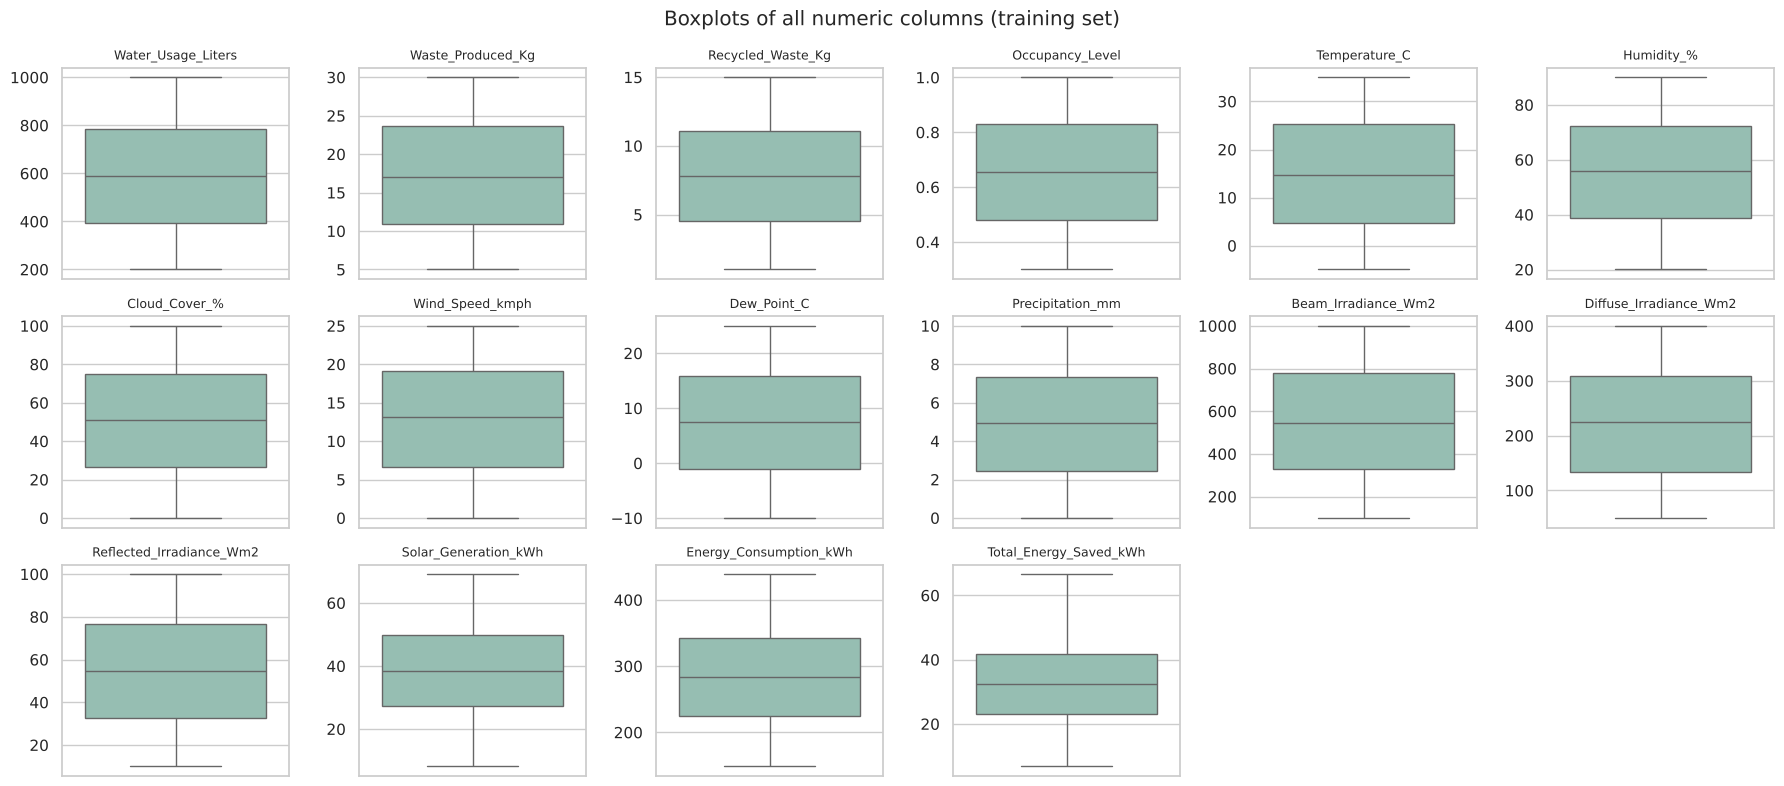

In [6]:
numeric_features = [c for c in train_df.select_dtypes('number').columns if c not in (TARGET, 'Is_Peak_Hour')]
cols_to_check = numeric_features + [TARGET]

q1, q3 = train_df[cols_to_check].quantile(0.25), train_df[cols_to_check].quantile(0.75)
iqr = q3 - q1
iqr_outliers = ((train_df[cols_to_check] < q1 - 1.5 * iqr) | (train_df[cols_to_check] > q3 + 1.5 * iqr)).sum()
z_outliers = (np.abs(zscore(train_df[cols_to_check])) > 3).sum()
print('Outliers by the IQR rule (outside Q1 - 1.5 IQR, Q3 + 1.5 IQR):', int(iqr_outliers.sum()))
print('Outliers by the z-score rule (|z| > 3)                      :', int(z_outliers.sum()))

fig, axes = plt.subplots(3, 6, figsize=(18, 8))
for ax, col in zip(axes.ravel(), cols_to_check):
    sns.boxplot(y=train_df[col], ax=ax, color='#8fc5b5')
    ax.set_title(col, fontsize=9)
    ax.set_ylabel('')
for ax in axes.ravel()[len(cols_to_check):]:
    ax.axis('off')
plt.suptitle('Boxplots of all numeric columns (training set)')
plt.tight_layout()
save_fig('01_boxplots')
plt.show()

**Decision:** there are **no outliers** by either rule. Every column stays inside a fixed range with values spread across it, and the target's
largest value is inside the normal range. Because nothing is extreme, **we do not remove or cap any rows**. Removing valid
rows would only reduce the training data. If there had been outliers, we would have checked whether they were errors or real values before deciding.

## 2.4 Exploring the data with visualizations

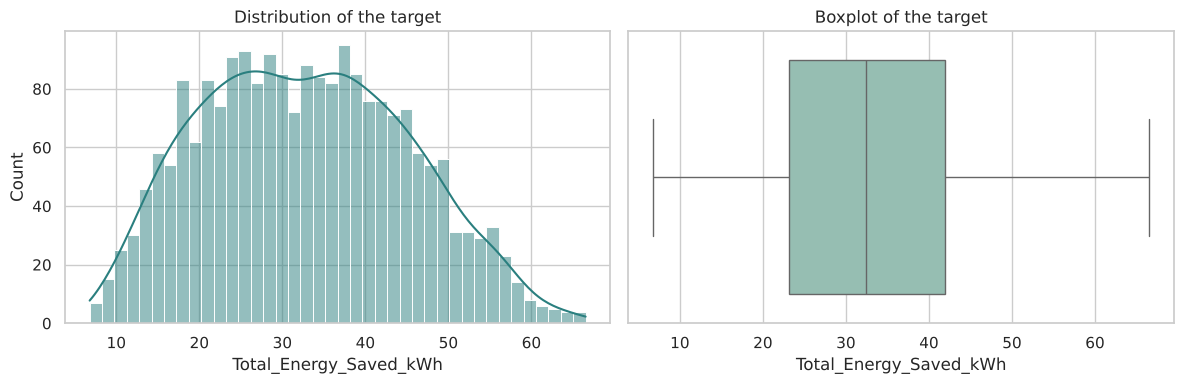

Target skewness: 0.18


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train_df[TARGET], bins=40, kde=True, ax=axes[0], color='#2a7f7f')
axes[0].set_title('Distribution of the target')
sns.boxplot(x=train_df[TARGET], ax=axes[1], color='#8fc5b5')
axes[1].set_title('Boxplot of the target')
plt.tight_layout()
save_fig('02_target_distribution')
plt.show()
print('Target skewness:', round(train_df[TARGET].skew(), 2))

Largest absolute skewness among the features: 0.08


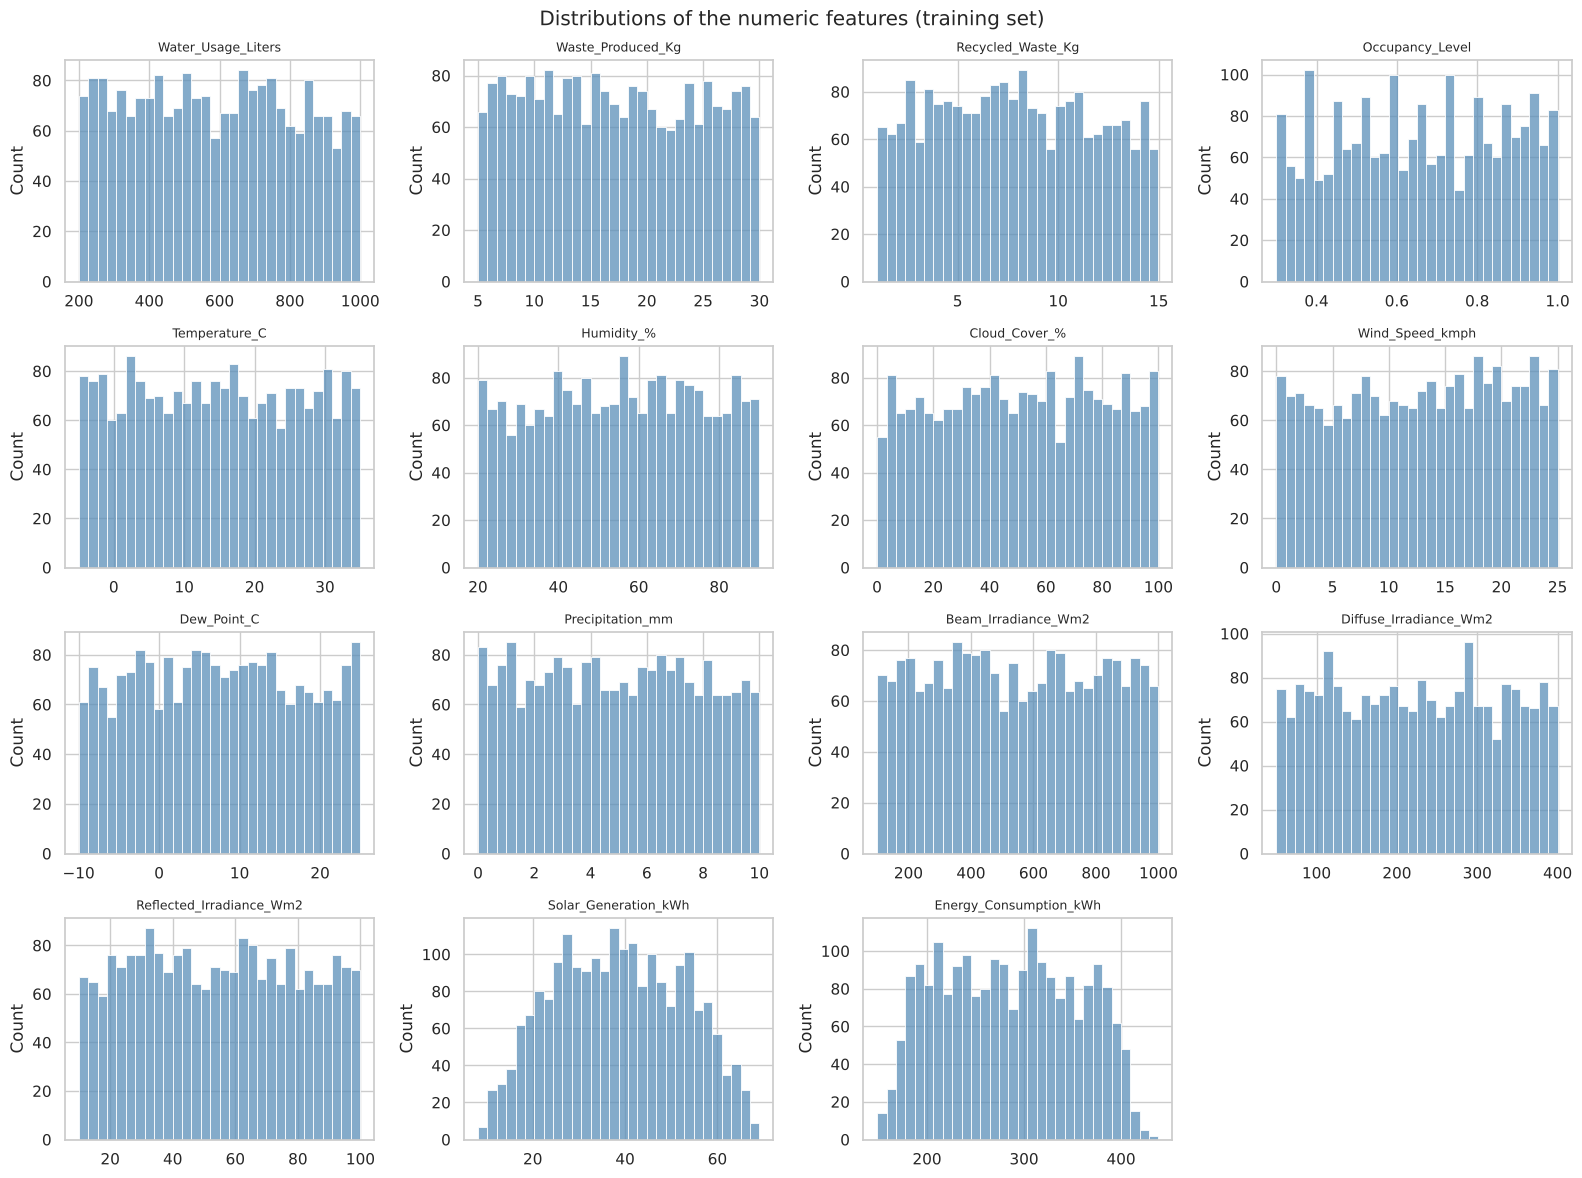

In [8]:
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.ravel(), numeric_features):
    sns.histplot(train_df[col], bins=30, ax=ax, color='#5b8fb9')
    ax.set_title(col, fontsize=9)
    ax.set_xlabel('')
for ax in axes.ravel()[len(numeric_features):]:
    ax.axis('off')
print('Largest absolute skewness among the features:', round(train_df[numeric_features].skew().abs().max(), 2))
plt.suptitle('Distributions of the numeric features (training set)')
plt.tight_layout()
save_fig('03_feature_distributions')
plt.show()

**Distributions:** the features are close to **evenly spread (uniform) across their ranges**, not bell-shaped, and the skewness values are all near zero.
So no log transform or other skew correction is needed. The target has a mild right tail. This pattern (every feature uniform, in a fixed range) suggests
the data was simulated rather than measured, which we keep in mind when we interpret the results.

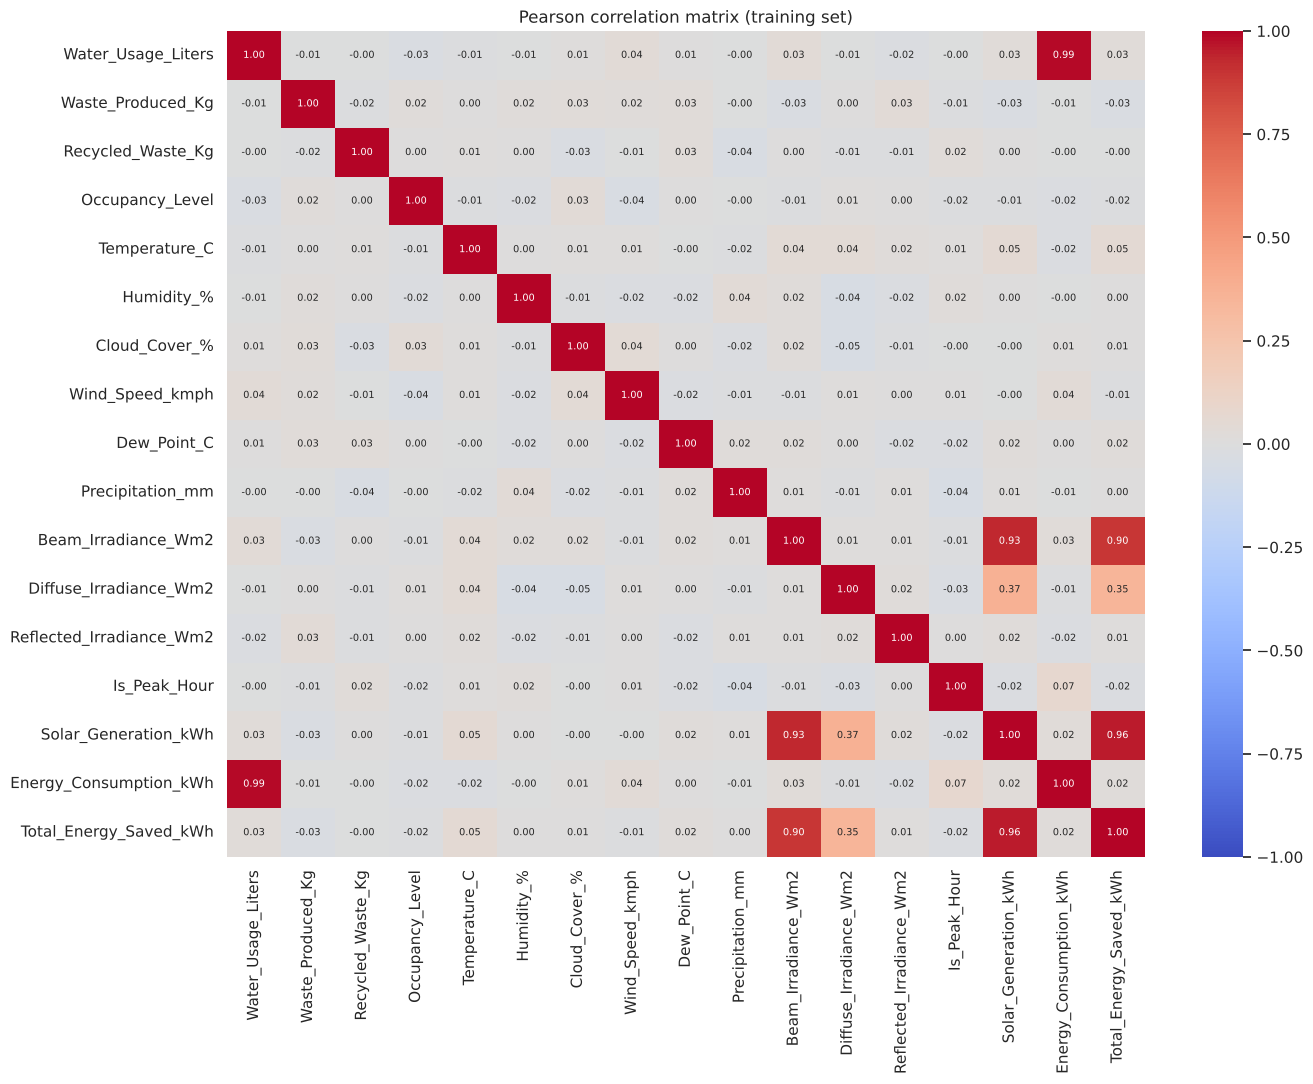

Solar_Generation_kWh        0.958
Beam_Irradiance_Wm2         0.896
Diffuse_Irradiance_Wm2      0.349
Temperature_C               0.054
Water_Usage_Liters          0.027
Dew_Point_C                 0.022
Energy_Consumption_kWh      0.022
Reflected_Irradiance_Wm2    0.013
Cloud_Cover_%               0.007
Humidity_%                  0.003
Precipitation_mm            0.002
Recycled_Waste_Kg          -0.002
Wind_Speed_kmph            -0.009
Occupancy_Level            -0.015
Is_Peak_Hour               -0.018
Waste_Produced_Kg          -0.027


In [9]:
corr = train_df.select_dtypes('number').corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0, annot_kws={'size': 7})
plt.title('Pearson correlation matrix (training set)')
plt.tight_layout()
save_fig('04_correlation_heatmap')
plt.show()
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_string())

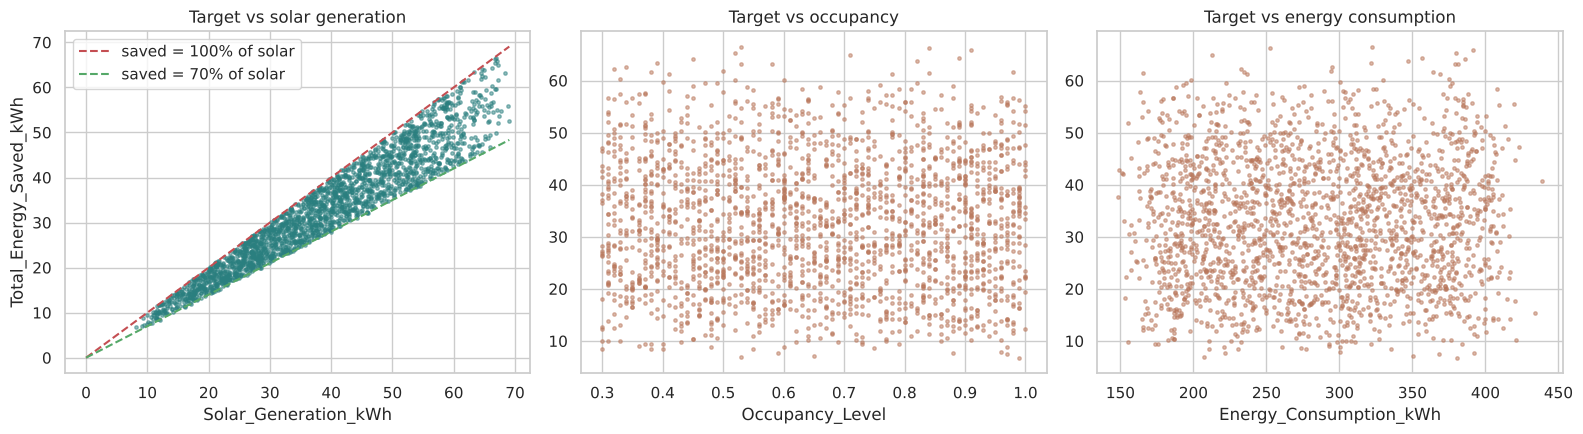

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
solar = train_df['Solar_Generation_kWh']
axes[0].scatter(solar, train_df[TARGET], s=6, alpha=0.5, color='#2a7f7f')
axes[0].plot([0, solar.max()], [0, solar.max()], 'r--', label='saved = 100% of solar')
axes[0].plot([0, solar.max()], [0, 0.7 * solar.max()], 'g--', label='saved = 70% of solar')
axes[0].set_xlabel('Solar_Generation_kWh'); axes[0].set_ylabel(TARGET); axes[0].legend(); axes[0].set_title('Target vs solar generation')
axes[1].scatter(train_df['Occupancy_Level'], train_df[TARGET], s=6, alpha=0.5, color='#b9775b')
axes[1].set_xlabel('Occupancy_Level'); axes[1].set_title('Target vs occupancy')
axes[2].scatter(train_df['Energy_Consumption_kWh'], train_df[TARGET], s=6, alpha=0.5, color='#b9775b')
axes[2].set_xlabel('Energy_Consumption_kWh'); axes[2].set_title('Target vs energy consumption')
plt.tight_layout()
save_fig('05_target_vs_features')
plt.show()

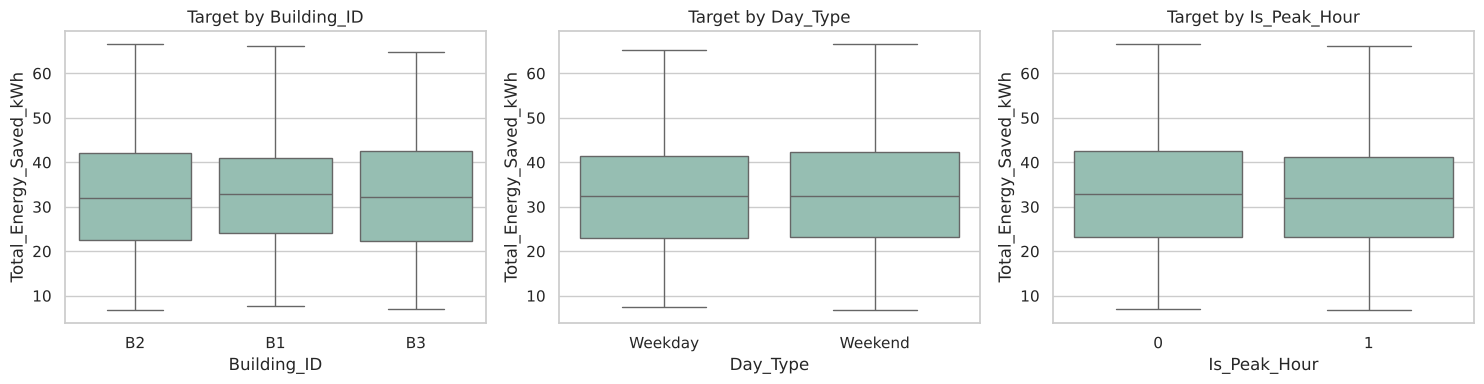

{'B1': 33.25, 'B2': 32.42, 'B3': 32.69} {'Weekday': 32.62, 'Weekend': 32.96}


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Building_ID', 'Day_Type', 'Is_Peak_Hour']):
    sns.boxplot(x=col, y=TARGET, data=train_df, ax=ax, color='#8fc5b5')
    ax.set_title(f'Target by {col}')
plt.tight_layout()
save_fig('06_target_by_category')
plt.show()
print(train_df.groupby('Building_ID')[TARGET].mean().round(2).to_dict(), train_df.groupby('Day_Type')[TARGET].mean().round(2).to_dict())

## 2.5 Relationship with the target: correlation, mutual information and VIF
We use the same measures as in the earlier assignment: Pearson (linear), Spearman (monotonic) and mutual information (any kind of dependency), then VIF to detect multicollinearity.

In [12]:
rows = []
for col in numeric_features:
    mi = mutual_info_regression(train_df[[col]].values, train_df[TARGET], random_state=RANDOM_STATE)[0]
    rows.append({'feature': col,
                 'pearson_r': pearsonr(train_df[col], train_df[TARGET])[0],
                 'spearman_rho': spearmanr(train_df[col], train_df[TARGET])[0],
                 'mutual_info': mi})
relation = pd.DataFrame(rows).sort_values('mutual_info', ascending=False).reset_index(drop=True)
print(relation.round(4).to_string())

                     feature  pearson_r  spearman_rho  mutual_info
0       Solar_Generation_kWh     0.9579        0.9636       1.4792
1        Beam_Irradiance_Wm2     0.8955        0.9059       0.8442
2     Diffuse_Irradiance_Wm2     0.3492        0.3286       0.1097
3           Precipitation_mm     0.0021        0.0012       0.0257
4                 Humidity_%     0.0033        0.0036       0.0160
5   Reflected_Irradiance_Wm2     0.0128        0.0130       0.0103
6                Dew_Point_C     0.0221        0.0196       0.0089
7            Occupancy_Level    -0.0153       -0.0115       0.0088
8              Cloud_Cover_%     0.0065        0.0032       0.0000
9          Waste_Produced_Kg    -0.0268       -0.0282       0.0000
10         Recycled_Waste_Kg    -0.0017       -0.0028       0.0000
11        Water_Usage_Liters     0.0270        0.0248       0.0000
12             Temperature_C     0.0536        0.0539       0.0000
13           Wind_Speed_kmph    -0.0088       -0.0077       0.

In [13]:
import warnings
X_vif = sm.add_constant(train_df[numeric_features + ['Is_Peak_Hour']])
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    vif = pd.DataFrame({'feature': X_vif.columns,
                        'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]})
vif = vif[vif.feature != 'const'].sort_values('VIF', ascending=False).reset_index(drop=True)
print(vif.round(2).to_string())

                     feature          VIF
0       Solar_Generation_kWh  23136843.45
1        Beam_Irradiance_Wm2  19955852.29
2     Diffuse_Irradiance_Wm2   3021812.61
3     Energy_Consumption_kWh        46.97
4         Water_Usage_Liters        46.74
5               Is_Peak_Hour         1.25
6            Occupancy_Level         1.01
7              Temperature_C         1.01
8              Cloud_Cover_%         1.01
9            Wind_Speed_kmph         1.01
10         Waste_Produced_Kg         1.01
11                Humidity_%         1.01
12          Precipitation_mm         1.01
13  Reflected_Irradiance_Wm2         1.00
14         Recycled_Waste_Kg         1.00
15               Dew_Point_C         1.00


Solar = a*Beam + b*Diffuse + c ->  a = 0.05  b = 0.05  c = -0.0001  R2 = 1.0

Energy saved / solar generation:
count    2138.000
mean        0.850
std         0.086
min         0.700
25%         0.774
50%         0.849
75%         0.926
max         1.000


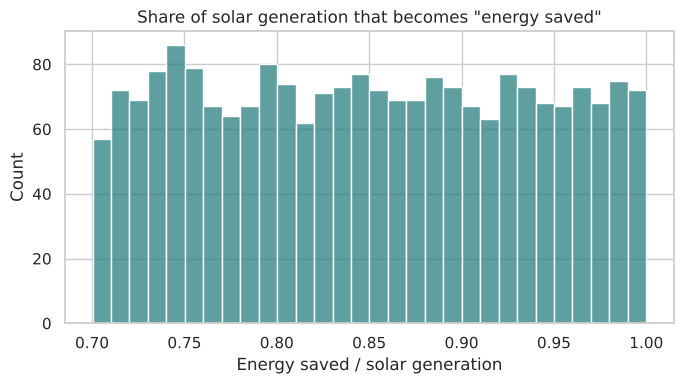

In [14]:
# How is the target related to solar generation, and solar generation to irradiance?
lr_solar = LinearRegression().fit(train_df[['Beam_Irradiance_Wm2', 'Diffuse_Irradiance_Wm2']], train_df['Solar_Generation_kWh'])
print('Solar = a*Beam + b*Diffuse + c ->  a =', lr_solar.coef_[0].round(4), ' b =', lr_solar.coef_[1].round(4), ' c =', round(lr_solar.intercept_, 4),
      ' R2 =', round(lr_solar.score(train_df[['Beam_Irradiance_Wm2', 'Diffuse_Irradiance_Wm2']], train_df['Solar_Generation_kWh']), 6))

ratio = train_df[TARGET] / train_df['Solar_Generation_kWh']
print()
print('Energy saved / solar generation:')
print(ratio.describe().round(3).to_string())

plt.figure(figsize=(7, 4))
sns.histplot(ratio, bins=30, color='#2a7f7f')
plt.xlabel('Energy saved / solar generation'); plt.title('Share of solar generation that becomes "energy saved"')
plt.tight_layout()
save_fig('07_saved_to_solar_ratio')
plt.show()

**Key findings**

1. **`Solar_Generation_kWh` is by far the strongest feature** (Pearson 0.958, the highest mutual information). `Beam_Irradiance_Wm2` follows (0.896) and
   `Diffuse_Irradiance_Wm2` is weaker (0.349). Almost every other feature, including water, waste, occupancy, weather and energy consumption, is close to **zero** on all three measures.
2. **The target is built from solar generation.** Energy saved is always between **70% and 100%** of solar generation (ratio min 0.70, max 1.00, mean 0.85).
   So the best any model can do is learn the average share (about 85%); the rest (the random 70-100% factor) cannot be predicted from the other columns.
3. **Multicollinearity:** `Solar_Generation_kWh` is exactly `0.05 x (Beam + Diffuse)`, so these three columns have VIF values in the millions. They are three copies of the same information.
4. The categorical columns (`Building_ID`, `Day_Type`, `Is_Peak_Hour`) show almost identical target distributions for every value, so they carry very little information.

## 2.6 Feature selection (step 1): remove redundant and unreliable columns

* **Remove `Beam_Irradiance_Wm2` and `Diffuse_Irradiance_Wm2`:** they are redundant, because `Solar_Generation_kWh` is exactly 0.05 x (Beam + Diffuse) and keeping all three gives infinite-like VIF.
  We keep the single column that is closest to the target.
* **Remove `Dew_Point_C`:** its values are physically impossible in a third of the rows (section 2.1) and it has no relationship with the target.
* **Keep the other 15 columns as candidates.** Instead of guessing which of them matter, step 2 of the selection is done **inside the model pipeline** with `SelectKBest`, and the number of features to keep is tuned by grid search in Stage 3. This way the selection is fitted only on training folds and cannot leak.

A note on leakage: `Solar_Generation_kWh` is a direct driver of the target (the target is 70-100% of it). It is still a legitimate feature because it is a sensor reading that is available when we want a prediction.
But it explains why one feature gives such a high score, so we report it openly.

In [15]:
feature_cols = [c for c in df.columns if c not in (TARGET, 'Beam_Irradiance_Wm2', 'Diffuse_Irradiance_Wm2', 'Dew_Point_C')]
cat_cols = ['Building_ID', 'Day_Type']
num_cols = [c for c in feature_cols if c not in cat_cols]

X_train, y_train = train_df[feature_cols], train_df[TARGET]
X_test, y_test = test_df[feature_cols], test_df[TARGET]
print(len(feature_cols), 'candidate features')
print('Categorical:', cat_cols)
print('Numeric    :', num_cols)

# F-scores on the training set only (used by SelectKBest)
f_scores, _ = f_regression(X_train[num_cols], y_train)
print()
print(pd.Series(f_scores, index=num_cols).sort_values(ascending=False).round(1).to_string())

15 candidate features
Categorical: ['Building_ID', 'Day_Type']
Numeric    : ['Water_Usage_Liters', 'Waste_Produced_Kg', 'Recycled_Waste_Kg', 'Occupancy_Level', 'Temperature_C', 'Humidity_%', 'Cloud_Cover_%', 'Wind_Speed_kmph', 'Precipitation_mm', 'Reflected_Irradiance_Wm2', 'Is_Peak_Hour', 'Solar_Generation_kWh', 'Energy_Consumption_kWh']

Solar_Generation_kWh        23762.9
Temperature_C                   6.2
Water_Usage_Liters              1.6
Waste_Produced_Kg               1.5
Energy_Consumption_kWh          1.0
Is_Peak_Hour                    0.7
Occupancy_Level                 0.5
Reflected_Irradiance_Wm2        0.4
Wind_Speed_kmph                 0.2
Cloud_Cover_%                   0.1
Humidity_%                      0.0
Precipitation_mm                0.0
Recycled_Waste_Kg               0.0


## 2.7 Encoding categorical features and scaling numeric features

* **Scaling:** numeric features use `StandardScaler` (mean 0, standard deviation 1). Ridge regression penalises large coefficients, so features on very different scales (water in hundreds, occupancy below 1) must be scaled to be treated fairly.
* **Encoding:** `Building_ID` and `Day_Type` are text and have **no natural order**. We compare three encoders inside the cross-validation pipeline, so the encoder is fitted on the training folds only:
  one-hot encoding, label (ordinal) encoding, and the CRC32 target encoder from the earlier assignment.

In [16]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def make_preprocess(kind):
    if kind == 'one-hot':
        cat = [('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)]
    elif kind == 'label (ordinal)':
        cat = [('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols)]
    else:  # CRC32 target encoding, one encoder per column
        cat = [(f'crc_{c}', CRCTargetEncoder(cols=[c], smoothing=1, min_samples_leaf=20, noise_scale=1e-3), [c]) for c in cat_cols]
    return ColumnTransformer([('num', StandardScaler(), num_cols)] + cat)


enc_rows = []
for kind in ['one-hot', 'label (ordinal)', 'CRC32 target']:
    pipe = Pipeline([('pre', make_preprocess(kind)), ('model', Ridge(alpha=1.0))])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='r2')
    enc_rows.append({'encoding': kind, 'cv_r2_mean': scores.mean(), 'cv_r2_std': scores.std()})
print(pd.DataFrame(enc_rows).round(4).to_string(index=False))

       encoding  cv_r2_mean  cv_r2_std
        one-hot      0.9163     0.0057
label (ordinal)      0.9162     0.0057
   CRC32 target      0.9163     0.0057


**Decision: one-hot encoding.** The three encoders give practically the same cross-validated R2 (0.9163 for one-hot, 0.9162 for label encoding and 0.9163 for CRC32 target encoding), so the choice does not change the result. We choose **one-hot** because
(1) it adds no artificial order (label encoding would say B1 < B2 < B3), (2) it does not use the target (target encoding needs extra care to avoid leakage), and (3) it only uses scikit-learn, which keeps deployment simple.
Target encoding is most useful for columns with many categories, and here there are only 3 and 2.

## 2.8 Feature engineering experiment
We tested three domain-inspired features: the **net energy balance** (solar generation minus consumption), the **energy used per occupant**, and the **recycling rate** (recycled divided by produced waste).
We keep them only if they improve the cross-validated score.

In [17]:
def add_features(d):
    d = d.copy()
    d['Net_Energy_Balance'] = d['Solar_Generation_kWh'] - d['Energy_Consumption_kWh']
    d['Energy_per_Occupant'] = d['Energy_Consumption_kWh'] / d['Occupancy_Level']
    d['Recycling_Rate'] = d['Recycled_Waste_Kg'] / d['Waste_Produced_Kg']
    return d


X_train_fe = add_features(X_train)
num_cols_fe = num_cols + ['Net_Energy_Balance', 'Energy_per_Occupant', 'Recycling_Rate']
pre_fe = ColumnTransformer([('num', StandardScaler(), num_cols_fe), ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
pre_base = make_preprocess('one-hot')

fe_rows = []
for name, pre, X_ in [('original features', pre_base, X_train), ('+ engineered features', pre_fe, X_train_fe)]:
    scores = cross_val_score(Pipeline([('pre', pre), ('model', Ridge(alpha=1.0))]), X_, y_train, cv=cv, scoring='r2')
    fe_rows.append({'feature set': name, 'cv_r2_mean': scores.mean(), 'cv_r2_std': scores.std()})
print(pd.DataFrame(fe_rows).round(4).to_string(index=False))
print('Rows where Recycling_Rate is above 1 (impossible):', int((X_train_fe['Recycling_Rate'] > 1).sum()))

          feature set  cv_r2_mean  cv_r2_std
    original features      0.9163     0.0057
+ engineered features      0.9159     0.0056
Rows where Recycling_Rate is above 1 (impossible): 303


**Decision: we do not keep the engineered features.** With the engineered features the cross-validated R2 is 0.9159, against 0.9163 without them, so there is **no improvement**. The reason is the data itself: the target depends only on solar generation, so combinations of other columns cannot add information.
The recycling rate would also be above 1 in some rows because of the inconsistent waste values from section 2.1. Honest negative results like this are part of the analysis.

# Stage 3: Modeling and tuning

## 3.1 Choosing the model
We compare four models with 5-fold cross-validation **on the training set**, all using the same preprocessing (scaling and one-hot encoding):
a **baseline** that always predicts the mean (an R2 of 0 means "no better than the mean"), **Ridge regression** (a linear model with a penalty on large coefficients),
**Random Forest** and **Gradient Boosting** (two tree-based models that can capture non-linear patterns).

In [18]:
preprocess = make_preprocess('one-hot')
candidates = {
    'Mean baseline': DummyRegressor(strategy='mean'),
    'Ridge regression': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=RANDOM_STATE),
}
cmp_rows = []
for name, model in candidates.items():
    res = cross_validate(Pipeline([('pre', preprocess), ('model', model)]), X_train, y_train, cv=cv,
                         scoring=('r2', 'neg_mean_absolute_error'))
    cmp_rows.append({'model': name, 'cv_r2': res['test_r2'].mean(), 'cv_r2_std': res['test_r2'].std(),
                     'cv_MAE': -res['test_neg_mean_absolute_error'].mean()})
model_comparison = pd.DataFrame(cmp_rows)
print(model_comparison.round(4).to_string(index=False))

            model   cv_r2  cv_r2_std  cv_MAE
    Mean baseline -0.0034     0.0038 10.3303
 Ridge regression  0.9163     0.0057  2.9015
    Random Forest  0.9113     0.0071  2.9622
Gradient Boosting  0.9104     0.0063  2.9717


**Choice: Ridge regression.** Cross-validated R2 is 0.9163 for Ridge, 0.9113 for Random Forest and 0.9104 for Gradient Boosting, while the mean baseline is at -0.003 (MAE 2.90, 2.96 and 2.97 kWh against 10.33 kWh for the baseline). The three real models are close (the gaps are within about one standard deviation across the folds), but Ridge is the highest and the simplest.
We choose it because (1) it has the best cross-validated score, (2) the relationship we found in the analysis is **linear** (energy saved is a share of solar generation), so a linear model is the right shape,
(3) the other 14 features are noise, and a penalised linear model ignores them more safely than a flexible tree model, which can fit noise, and (4) it is simple, fast and easy to explain and to deploy.

## 3.2 Grid search

The pipeline is `preprocess -> SelectKBest -> Ridge`. The grid search tunes two things with 5-fold cross-validation on the training set:

* `select__k`: how many of the 18 preprocessed columns to keep (the feature selection of section 2.6, step 2). Because it is inside the pipeline, the selection is re-fitted on each training fold.
* `model__alpha`: the strength of the Ridge penalty.

In [19]:
pipe = Pipeline([('pre', make_preprocess('one-hot')),
                 ('select', SelectKBest(score_func=f_regression)),
                 ('model', Ridge())])

param_grid = {
    'select__k': [1, 2, 3, 5, 10, 'all'],
    'model__alpha': [0.01, 0.1, 1, 10, 100],
}
print('Parameter grid:', param_grid)
print('Combinations  :', 6 * 5, '| fits (5 folds):', 6 * 5 * 5)

grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='r2', n_jobs=-1, return_train_score=True)
grid.fit(X_train, y_train)

print()
print('Best parameters      :', grid.best_params_)
print('Best CV R2 (5-fold)  :', round(grid.best_score_, 4))
results = pd.DataFrame(grid.cv_results_)
top = results.sort_values('rank_test_score')[['param_select__k', 'param_model__alpha', 'mean_test_score', 'std_test_score', 'mean_train_score']].head(8)
print()
print(top.round(5).to_string(index=False))

Parameter grid: {'select__k': [1, 2, 3, 5, 10, 'all'], 'model__alpha': [0.01, 0.1, 1, 10, 100]}
Combinations  : 30 | fits (5 folds): 150



Best parameters      : {'model__alpha': 1, 'select__k': 1}
Best CV R2 (5-fold)  : 0.917

param_select__k  param_model__alpha  mean_test_score  std_test_score  mean_train_score
              1                1.00          0.91699         0.00575           0.91753
              1                0.10          0.91699         0.00575           0.91753
              1                0.01          0.91699         0.00575           0.91753
              1               10.00          0.91697         0.00582           0.91750
              2                1.00          0.91694         0.00577           0.91754
              2                0.10          0.91694         0.00577           0.91754
              2                0.01          0.91694         0.00577           0.91754
              2               10.00          0.91692         0.00584           0.91751


Best CV R2 for each number of kept features:
param_select__k
1      0.91699
2      0.91694
3      0.91692
5      0.91688
10     0.91651
all    0.91629


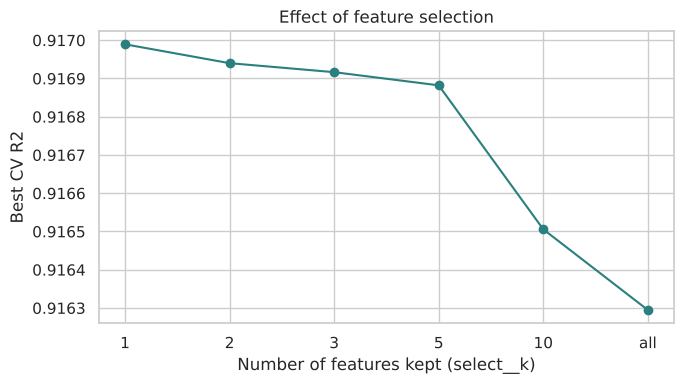

Features kept by the best model: ['num__Solar_Generation_kWh']
Coefficients                    : {'num__Solar_Generation_kWh': np.float64(11.829)} | intercept: 32.792


In [20]:
# How the score depends on the number of selected features (best alpha for each k)
by_k = results.groupby(results['param_select__k'].astype(str))['mean_test_score'].max()
order = ['1', '2', '3', '5', '10', 'all']
print('Best CV R2 for each number of kept features:')
print(by_k.reindex(order).round(5).to_string())
plt.figure(figsize=(7, 4))
plt.plot(order, [by_k[k] for k in order], 'o-', color='#2a7f7f')
plt.xlabel('Number of features kept (select__k)'); plt.ylabel('Best CV R2'); plt.title('Effect of feature selection')
plt.tight_layout()
save_fig('08_grid_search_k')
plt.show()

best_pipe = grid.best_estimator_
pre_fit, sel_fit, model_fit = best_pipe.named_steps['pre'], best_pipe.named_steps['select'], best_pipe.named_steps['model']
kept = list(pre_fit.get_feature_names_out()[sel_fit.get_support()])
print('Features kept by the best model:', kept)
print('Coefficients                    :', dict(zip(kept, model_fit.coef_.round(3))), '| intercept:', round(model_fit.intercept_, 3))

**Result of the tuning:** the best combination is `select__k = 1` and `model__alpha = 1`, with a 5-fold cross-validated R2 of **0.9170**. Only one feature is kept, `Solar_Generation_kWh`. Keeping more features never helps: the best score falls slowly from 0.91699 (1 feature) to 0.91629 (all 18 columns). The alpha values 0.01, 0.1 and 1 give the same score to five decimals, because the model has one coefficient fitted on about 2,000 rows, so the penalty has almost no effect. The tuned model is therefore a straight line from solar generation to energy saved, and the training score (0.9175) is close to the cross-validation score, so it is not overfitting.

# Stage 4: Evaluation on the test set

The test set was not used for any decision so far (not for scaling, encoding, selection, model choice or tuning), so it gives an honest estimate of performance on new data.

In [21]:
y_pred_test = best_pipe.predict(X_test)
y_pred_train = best_pipe.predict(X_train)

metrics = {
    'R2':   r2_score(y_test, y_pred_test),
    'MAE':  mean_absolute_error(y_test, y_pred_test),
    'RMSE': float(np.sqrt(mean_squared_error(y_test, y_pred_test))),
}
print('Test set  : R2 = %.4f | MAE = %.3f kWh | RMSE = %.3f kWh' % (metrics['R2'], metrics['MAE'], metrics['RMSE']))
print('Target std on the test set: %.3f kWh (the error to beat is RMSE < this)' % y_test.std())
print()
print('Overfitting check (R2):  train = %.4f | 5-fold CV = %.4f | test = %.4f'
      % (r2_score(y_train, y_pred_train), grid.best_score_, metrics['R2']))

Test set  : R2 = 0.9131 | MAE = 2.856 kWh | RMSE = 3.479 kWh
Target std on the test set: 11.809 kWh (the error to beat is RMSE < this)

Overfitting check (R2):  train = 0.9175 | 5-fold CV = 0.9170 | test = 0.9131


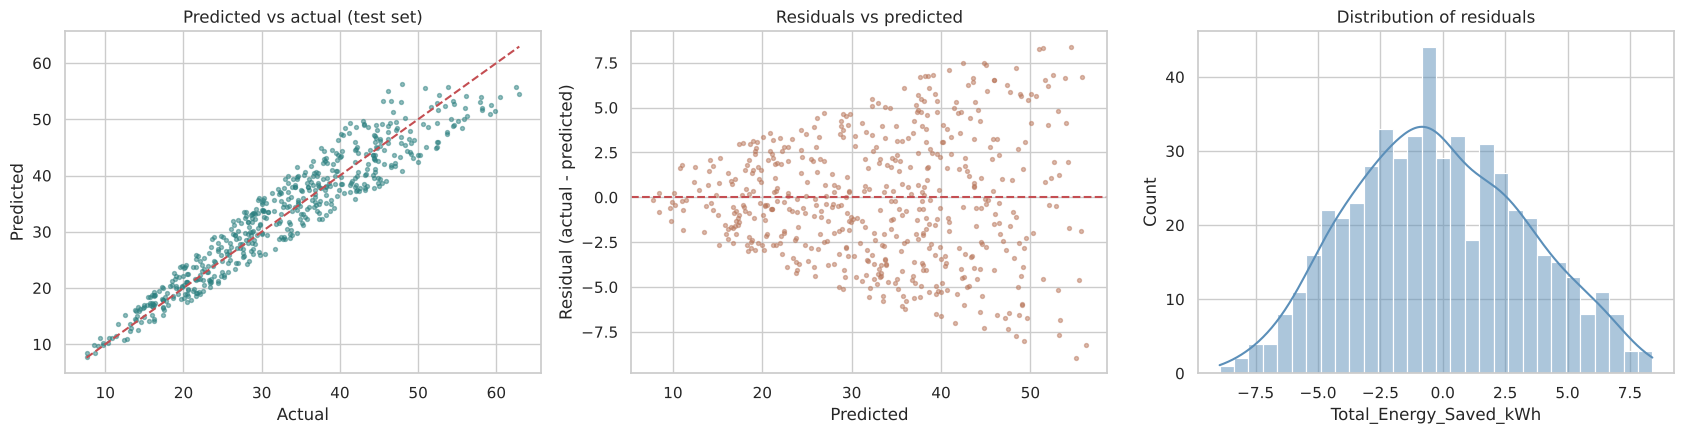

                        MAE  residual_std
Solar_Generation_kWh                     
low solar             1.736         2.080
medium solar          2.944         3.402
high solar            3.896         4.522


In [22]:
resid = y_test - y_pred_test
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(y_test, y_pred_test, s=8, alpha=0.5, color='#2a7f7f')
lims = [min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())]
axes[0].plot(lims, lims, 'r--'); axes[0].set_xlabel('Actual'); axes[0].set_ylabel('Predicted'); axes[0].set_title('Predicted vs actual (test set)')
axes[1].scatter(y_pred_test, resid, s=8, alpha=0.5, color='#b9775b')
axes[1].axhline(0, color='r', linestyle='--'); axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Residual (actual - predicted)'); axes[1].set_title('Residuals vs predicted')
sns.histplot(resid, bins=30, kde=True, ax=axes[2], color='#5b8fb9'); axes[2].set_title('Distribution of residuals')
plt.tight_layout()
save_fig('09_evaluation')
plt.show()

# Where does the model struggle? Error by amount of solar generation
solar_group = pd.qcut(test_df['Solar_Generation_kWh'], 3, labels=['low solar', 'medium solar', 'high solar'])
by_group = pd.DataFrame({'MAE': resid.abs().groupby(solar_group).mean(), 'residual_std': resid.groupby(solar_group).std()})
print(by_group.round(3).to_string())

In [23]:
# How good could ANY model be? The unpredictable part is the random 70-100% factor.
ratio_tr = y_train / X_train['Solar_Generation_kWh']
noise_var = ratio_tr.var() * (X_train['Solar_Generation_kWh'] ** 2).mean()
ceiling_r2 = 1 - noise_var / y_train.var()
print('Estimated best possible R2 given the random factor: %.3f' % ceiling_r2)
print('Our test R2: %.3f' % metrics['R2'])

Estimated best possible R2 given the random factor: 0.918
Our test R2: 0.913


**Evaluation summary**

* **Performance:** on the test set the model reaches **R2 = 0.913**, **MAE = 2.86 kWh** and **RMSE = 3.48 kWh**, compared with a target standard deviation of 11.81 kWh. It explains about 91.3% of the variation in energy saved.
* **Overfitting:** none. The scores on the training data (0.9175), in cross-validation (0.9170) and on the test set (0.913) are practically identical. This is expected, because the final model is essentially one coefficient and an intercept.
* **Where it struggles:** the errors grow with solar generation (residual standard deviation 2.08 for low, 3.40 for medium and 4.52 kWh for high solar). The reason is that the unknown factor is a **percentage** (70-100%) of solar generation, so the same percentage gap means more kWh when generation is high.
* **Limit of the data:** the remaining error is **not a model weakness**. The target contains a random 70-100% factor that no column explains. The estimated best possible R2 is about 0.918, and our model is at 0.913, so more tuning or a more complex model cannot help.
* **Caution:** the data looks simulated (all features uniform and independent), so the results should not be assumed to carry over to a real campus without re-checking on real measurements.

# Stage 5 (preparation): saving the model and preprocessing objects

The fitted pipeline is split into its parts and saved as **pickle files** in `models/`, together with a small dictionary (`feature_info.pkl`) that the Streamlit app uses to build the input form.
We then reload the files and check that they give the same predictions as the pipeline.

In [24]:
# Which ORIGINAL columns does the selected model actually use?
selected_raw = []
for name in kept:
    prefix, _, rest = name.partition('__')
    raw = rest if prefix == 'num' else next(c for c in cat_cols if rest.startswith(c + '_'))
    if raw not in selected_raw:
        selected_raw.append(raw)
selected_raw = [c for c in feature_cols if c in selected_raw]          # keep the original column order
print('Original columns used by the model:', selected_raw)

# Prediction range: 5th and 95th percentile of (actual / predicted) on the training data
ratio_q = np.quantile(y_train / y_pred_train, [0.05, 0.95])
inside = ((y_test >= y_pred_test * ratio_q[0]) & (y_test <= y_pred_test * ratio_q[1])).mean()
print('Range multipliers:', ratio_q.round(3), '| share of test rows inside the range:', round(float(inside), 3))

feature_info = {
    'feature_cols': feature_cols,
    'num_cols': num_cols,
    'cat_cols': cat_cols,
    'selected_raw_features': selected_raw,
    'defaults': {c: (float(X_train[c].median()) if c in num_cols else str(X_train[c].mode()[0])) for c in feature_cols},
    'ranges': {c: [float(X_train[c].min()), float(X_train[c].max())] for c in num_cols},
    'categories': {c: sorted(str(v) for v in X_train[c].unique()) for c in cat_cols},
    'irradiance_ranges': {c: [float(train_df[c].min()), float(train_df[c].max())] for c in ['Beam_Irradiance_Wm2', 'Diffuse_Irradiance_Wm2']},
    'solar_from_irradiance_factor': 0.05,
    'saved_to_solar_ratio': [float(ratio.min()), float(ratio.mean()), float(ratio.max())],
    'range_multipliers': [float(ratio_q[0]), float(ratio_q[1])],
    'metrics': {'test_r2': float(metrics['R2']), 'test_mae': float(metrics['MAE']), 'test_rmse': float(metrics['RMSE']),
                'cv_r2': float(grid.best_score_)},
    'best_params': {k: (v if isinstance(v, str) else float(v)) for k, v in grid.best_params_.items()},
    'versions': {'scikit-learn': sklearn.__version__, 'pandas': pd.__version__, 'numpy': np.__version__},
}
json.dumps(feature_info)      # raises an error if something is not a plain Python type

artifacts = {'preprocessor': pre_fit, 'selector': sel_fit, 'model': model_fit, 'feature_info': feature_info}
for name, obj in artifacts.items():
    with open(f'models/{name}.pkl', 'wb') as f:
        pickle.dump(obj, f)
print('Saved:', sorted(os.listdir('models')))

Original columns used by the model: ['Solar_Generation_kWh']
Range multipliers: [0.843 1.159] | share of test rows inside the range: 0.914
Saved: ['feature_info.pkl', 'model.pkl', 'preprocessor.pkl', 'selector.pkl']


In [25]:
# Reload the pickles and compare with the pipeline
loaded = {}
for name in artifacts:
    with open(f'models/{name}.pkl', 'rb') as f:
        loaded[name] = pickle.load(f)

X_check = loaded['selector'].transform(loaded['preprocessor'].transform(X_test))
pred_check = loaded['model'].predict(X_check)
print('Identical to the pipeline predictions:', bool(np.allclose(pred_check, y_pred_test)))

# Three sample inputs to test the deployed app with (all other columns at their typical value)
samples = {'Low solar': 15.0, 'Typical solar': 38.6, 'High solar': 60.0}
for label, solar_value in samples.items():
    row = pd.DataFrame([feature_info['defaults']])
    row['Solar_Generation_kWh'] = solar_value
    p = loaded['model'].predict(loaded['selector'].transform(loaded['preprocessor'].transform(row[feature_cols])))[0]
    lo, hi = p * feature_info['range_multipliers'][0], p * feature_info['range_multipliers'][1]
    print(f'{label:14s} solar = {solar_value:5.1f} kWh -> predicted energy saved = {p:6.2f} kWh (range {lo:.2f} to {hi:.2f})')

Identical to the pipeline predictions: True
Low solar      solar =  15.0 kWh -> predicted energy saved =  12.84 kWh (range 10.83 to 14.88)
Typical solar  solar =  38.6 kWh -> predicted energy saved =  32.79 kWh (range 27.65 to 37.99)
High solar     solar =  60.0 kWh -> predicted energy saved =  50.88 kWh (range 42.91 to 58.95)
